# RideFast — Operational & Growth Diagnostics (EDA)

**Goal:** diagnose why a ride-hailing platform (12 cities, 35k users, 8k drivers) is leaking rides, revenue and users, and turn the findings into actions.

**Data:** 4 related tables — `rides` (120,000 requests, Jul 2023 – Jun 2024), `drivers` (8,000), `users` (35,000), `support_tickets` (22,000).

**Flow:** data quality → funnel → city & zone → wait time → promotions → retention → support → summary.

In [1]:
import pandas as pd
import charts
import matplotlib.pyplot as plt
from pipeline import load_raw, validate, engineer, build_tables
import charts

pd.set_option("display.float_format", "{:,.4f}".format)
dfs = load_raw()
{name: df.shape for name, df in dfs.items()}

{'rides': (120000, 18), 'drivers': (8000, 10), 'users': (35000, 8), 'tickets': (22000, 9)}

## 1. Data quality
Every key, foreign key and business rule is checked before any metric is calculated.

In [2]:
validate(dfs)

check,failing_rows,passed
rides: duplicate ride_id,0,True
drivers: duplicate driver_id,0,True
users: duplicate user_id,0,True
tickets: duplicate ticket_id,0,True
rides: user_id not in users,0,True
rides: driver_id not in drivers,0,True
rides: unknown status,0,True
rides: pickup before request,0,True
rides: completed with no dropoff,0,True
rides: non-completed with fare > 0,0,True


In [3]:
dfs = engineer(dfs)
t = build_tables(dfs)
t["kpi_headline"]

metric,value
ride_requests,"120,000.0000"
completed_rides,"97,638.0000"
completion_rate,0.8136
driver_cancel_rate,0.0926
avg_wait_min,7.8412
median_wait_min,7.0000
completed_revenue,"3,583,767.9600"
avg_completed_fare,36.7046
promo_usage_rate,0.1564
total_promo_discount,"179,213.6300"


## 2. Ride funnel — where requests leak
18.6% of requests never become a ride; driver cancellation is the biggest single leak. Failed rides also had longer waits.

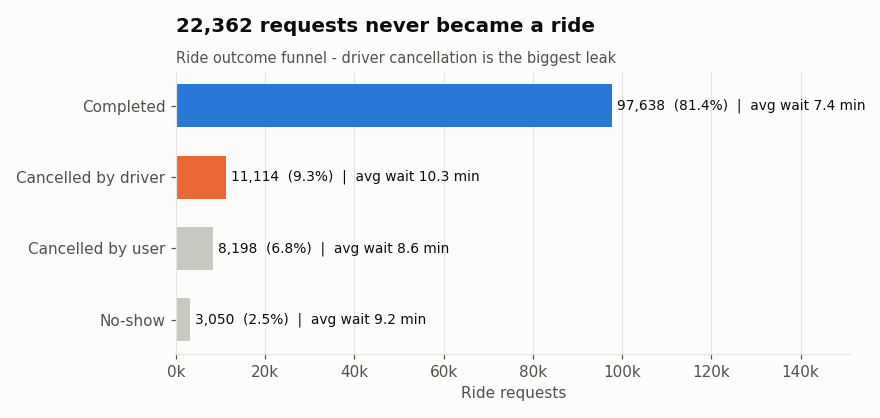

status,requests,avg_wait_min,share
completed,97638,7.4478,0.8136
cancelled_driver,11114,10.3289,0.0926
cancelled_user,8198,8.6403,0.0683
no_show,3050,9.2246,0.0254


In [4]:
charts.status_leakage(t["kpi_status_funnel"])
t["kpi_status_funnel"]

## 3. City view — Northgate is the outlier

In [5]:
t['kpi_northgate_vs_rest']

group,requests,completed,completion_rate,driver_cancel_rate,avg_wait_min,avg_user_rating,promo_rate,revenue
Northgate,9989,7606,0.7614,0.1295,13.3515,3.9678,0.1604,"274,724.6500"
Other 11 cities,110011,90032,0.8184,0.0893,7.3409,4.2150,0.1560,"3,309,043.3100"


### Zone drill-down
The Northgate problem is **not city-wide**: 6 of its 8 zones perform in line with the network. `NOR-Z04` and `NOR-Z05` (≈23 min average wait, ≈65.5% completion) pull the whole city down.

In [6]:
z = t["kpi_zone"]
z[z["city"] == "Northgate"][["pickup_zone", "requests", "completion_rate", "driver_cancel_rate", "avg_wait_min", "avg_user_rating"]]

pickup_zone,requests,completion_rate,driver_cancel_rate,avg_wait_min,avg_user_rating
NOR-Z05,1967,0.6548,0.2018,22.9390,3.5202
NOR-Z04,1867,0.6561,0.2046,22.9989,3.5322
NOR-Z06,989,0.8049,0.0991,7.4024,4.1922
NOR-Z02,1038,0.8131,0.0886,7.4046,4.1600
NOR-Z07,1012,0.8271,0.0751,7.3370,4.1983
NOR-Z08,1010,0.8337,0.0733,7.4743,4.1793
NOR-Z03,1035,0.8367,0.0879,7.1971,4.1998
NOR-Z01,1071,0.8478,0.0784,7.3557,4.1850


In [7]:
network = dfs["rides"]["is_completed"].mean()
bad = z[z["pickup_zone"].isin(["NOR-Z04", "NOR-Z05"])]
lost_rides = ((network - bad["completion_rate"]) * bad["requests"]).sum()
avg_fare = t["kpi_headline"].set_index("metric").loc["avg_completed_fare", "value"]
print(f"Rides lost vs network average in NOR-Z04/Z05: {lost_rides:,.0f}")
print(f"Revenue opportunity at avg completed fare (${avg_fare:.2f}): ${lost_rides * avg_fare:,.0f} per year")

Rides lost vs network average in NOR-Z04/Z05: 607
Revenue opportunity at avg completed fare ($36.70): $22,265 per year


Driver-side metrics for Northgate look like every other city, which points to **zone-level dispatch / coverage** rather than poor driver quality.

In [8]:
t['kpi_driver_city'].sort_values('avg_cancellation', ascending=False).head(5)

city,drivers,active_share,avg_acceptance,avg_cancellation,avg_online_hrs,avg_rating
Westville,613,0.7863,0.7945,0.1457,95.8941,4.1372
Clearwater,662,0.7885,0.8029,0.1438,96.7856,4.1261
Northgate,731,0.7839,0.8064,0.1427,97.6940,4.1289
Summit Town,650,0.7677,0.7943,0.1401,92.5625,4.1332
Lakewood,661,0.7700,0.7988,0.1394,97.1688,4.1427


## 4. Wait time is the leading indicator of failure

In [9]:
t['kpi_wait_bucket'][['wait_bucket', 'requests', 'completion_rate', 'driver_cancel_rate', 'avg_user_rating']]

wait_bucket,requests,completion_rate,driver_cancel_rate,avg_user_rating
0-5 min,30685,0.8617,0.0583,4.3098
5-10 min,53352,0.8435,0.0710,4.2642
10-15 min,26831,0.7815,0.1154,4.1152
15-20 min,6646,0.5409,0.2928,3.2729
20+ min,2486,0.6557,0.1991,3.5264


## 5. Promotions — cost without conversion uplift
Promo and non-promo requests complete at the same rate (81.4%). The promo fare gap (~$9.58) is almost exactly the average discount ($9.55): the discount is subsidy, not incremental demand.

In [10]:
t['kpi_promo']

promo_code_used,requests,completion_rate,avg_discount,avg_completed_fare
False,101232,0.8136,0.0000,38.2035
True,18768,0.8139,9.5489,28.6236


## 6. Retention

In [11]:
t['kpi_user_segments']

segment,users,avg_lifetime_rides,avg_promo_rides,avg_wallet_balance
Active,7133,34.1000,11.2000,69.5500
Churned,27867,30.1100,3.3100,39.8900


## 7. Customer support

In [12]:
t['kpi_ticket_category']

category_label,tickets,unresolved_rate,avg_resolution_hrs
App Issue,4983,0.1800,3.8313
Driver Behaviour,4868,0.1802,5.9354
Fare Dispute,4642,0.1855,3.8641
Lost Item,4212,0.1657,4.0444
Safety,3295,0.1812,5.3328


## 8. Summary

| # | Problem | Evidence | Action |
|---|---------|----------|--------|
| 1 | Northgate reliability | 76.1% completion vs 81.8% elsewhere; 2 zones at ~23 min wait | Zone recovery plan for NOR-Z04/Z05: driver positioning, dispatch audit, pickup SLA |
| 2 | Promotions not incremental | Same 81.4% completion; ~$179k discount spend | Replace blanket discounts with holdout-controlled, segmented tests |
| 3 | Retention | 79.6% of users churned | Lifecycle program: onboarding, service recovery, win-back |
| 4 | Support friction | 22k tickets, 17.9% unresolved | Map app issues to releases; SLA for safety & driver-behaviour tickets |
| 5 | Cancellation leakage | 22,362 failed requests; completion drops from 86% (<5 min) to 54% (15–20 min) | Wait-time alerting and cancellation dashboard by city × zone × hour |